<a href="https://colab.research.google.com/github/SaloMunoz1106/Reto-Analisis-Portafolio/blob/main/Copia_de_EDA_Portafolio_salome.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Mini-proyecto: EDA de un portafolio de activos
### Matplotlib · Seaborn · Pandas · yfinance

**Curso:** Lenguajes de Programación — Ingeniería Financiera  
**Sesión:** S18 — EDA y visualización de un portafolio  
**Estudiante:** Valentina _______________  
**Fecha:** _______________

---

## Objetivo

Realizar un análisis exploratorio de datos (EDA) de un portafolio de **5 activos** siguiendo los 10 pasos del mini-proyecto, responder el **reto final** y las **preguntas de profundización** de la guía S18 (número de *bins*, regla de Tukey, correlación vs. causalidad y diversificación).

### Activos elegidos y por qué

En lugar de tomar cinco empresas tecnológicas (que tienden a moverse juntas), elegí activos de **sectores distintos**, para que la pregunta de diversificación tenga más contenido:

| Ticker | Activo | Sector / tipo |
|---|---|---|
| `NVDA` | NVIDIA | Tecnología (semiconductores) |
| `MSFT` | Microsoft | Tecnología (software) |
| `JPM` | JPMorgan Chase | Financiero (banca) |
| `XOM` | Exxon Mobil | Energía (petróleo) |
| `GLD` | SPDR Gold Shares | ETF de oro (*commodity*) |

Incluir dos tecnológicas permite comparar un par del **mismo sector** contra pares de **sectores diferentes**.

**Período:** 1 de enero de 2024 – 31 de diciembre de 2025, frecuencia diaria.

> *Nota:* los textos de interpretación que dependen de los números se generan automáticamente a partir de los datos descargados (con `display(Markdown(...))`), para que las conclusiones siempre coincidan con los resultados de la ejecución.

In [1]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
%matplotlib inline

def pct(x, d=2):
    # Formatea un número como porcentaje
    return f"{x*100:.{d}f}%"

# Paso 1 — Datos

Descargo los precios históricos con `yfinance`. Uso `auto_adjust=True` para que los precios queden ajustados por dividendos y *splits* (importante en NVDA, que hizo un *split* 10:1 en junio de 2024: sin el ajuste aparecería una "caída" de 90% que no es real).

In [2]:
activos = ["NVDA", "MSFT", "JPM", "XOM", "GLD"]
inicio, fin = "2024-01-01", "2026-01-01"

precios = yf.download(
    activos,
    start=inicio,
    end=fin,
    auto_adjust=True,
    progress=False
)

precios.head()

Price            Close                                                \
Ticker             GLD         JPM        MSFT       NVDA        XOM   
Date                                                                   
2024-01-02  190.720001  161.472702  363.117920  48.028793  93.601601   
2024-01-03  189.130005  160.768936  362.853546  47.431522  94.388023   
2024-01-04  189.320007  161.835815  360.249176  47.859283  93.565010   
2024-01-05  189.350006  162.647781  360.063202  48.955101  93.848488   
2024-01-08  187.869995  162.411728  366.858063  52.101990  92.284821   

Price             High                                                ...  \
Ticker             GLD         JPM        MSFT       NVDA        XOM  ...   
Date                                                                  ...   
2024-01-02  191.889999  161.557151  368.042780  49.152535  94.278281  ...   
2024-01-03  189.860001  161.435163  365.457949  48.044743  94.753799  ...   
2024-01-04  189.750000  163.667458  365.301323  48.359832  95.622489  ...   
2024-01-05  191.259995  163.695782  364.283111  49.403801  94.552607  ...   
2024-01-08  188.740005  162.732734  367.357412  52.123929  92.394555  ...   

Price             Open                                                 Volume  \
Ticker             GLD         JPM        MSFT       NVDA        XOM      GLD   
Date                                                                            
2024-01-02  191.440002  158.667005  366.045412  49.101684  92.284812  6025600   
2024-01-03  188.770004  161.266265  361.296785  47.347766  93.519306  8661600   
2024-01-04  189.080002  161.108820  362.922123  47.628948  95.174418  4416700   
2024-01-05  189.679993  161.892463  361.257702  48.321938  94.342284  7481900   
2024-01-08  187.210007  162.411728  361.580713  49.368914  92.111083  6215000   

Price                                                
Ticker           JPM      MSFT       NVDA       XOM  
Date                                                 
2024-01-02   9977400  25258600  411254000  23483000  
2024-01-03   9852300  23083500  320896000  23490800  
2024-01-04  11972500  20901500  306535000  19395200  
2024-01-05  10066000  21004600  415039000  15827400  
2024-01-08  11229900  23134000  642510000  23370100  

[5 rows x 25 columns]

# Paso 2 — Calidad de los datos

Antes de graficar reviso dimensiones, tipos, valores faltantes y período.

In [3]:
print("Dimensiones:", precios.shape)
print()
precios.info()

Dimensiones: (502, 25)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 502 entries, 2024-01-02 to 2025-12-31
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, GLD)    502 non-null    float64
 1   (Close, JPM)    502 non-null    float64
 2   (Close, MSFT)   502 non-null    float64
 3   (Close, NVDA)   502 non-null    float64
 4   (Close, XOM)    502 non-null    float64
 5   (High, GLD)     502 non-null    float64
 6   (High, JPM)     502 non-null    float64
 7   (High, MSFT)    502 non-null    float64
 8   (High, NVDA)    502 non-null    float64
 9   (High, XOM)     502 non-null    float64
 10  (Low, GLD)      502 non-null    float64
 11  (Low, JPM)      502 non-null    float64
 12  (Low, MSFT)     502 non-null    float64
 13  (Low, NVDA)     502 non-null    float64
 14  (Low, XOM)      502 non-null    float64
 15  (Open, GLD)     502 non-null    float64
 16  (Open, JPM)     502 non-null    float

In [4]:
precios.describe().round(2)

Price    Close                                    High                  \
Ticker     GLD     JPM    MSFT    NVDA     XOM     GLD     JPM    MSFT   
count   502.00  502.00  502.00  502.00  502.00  502.00  502.00  502.00   
mean    269.31  233.92  436.39  130.43  106.38  270.48  235.97  439.90   
std      59.43   46.11   44.59   36.48    6.05   59.84   46.57   44.66   
min     184.42  157.76  350.45   47.43   88.52  184.88  158.17  360.25   
25%     220.57  192.31  404.58  107.88  102.99  221.60  195.46  407.84   
50%     251.09  231.49  420.49  129.62  107.07  252.26  233.92  423.63   
75%     308.27  280.00  475.53  157.79  110.71  309.28  282.22  480.12   
max     416.74  322.95  537.65  206.55  118.61  418.45  324.61  550.01   

Price                   ...    Open                                  \
Ticker    NVDA     XOM  ...     GLD     JPM    MSFT    NVDA     XOM   
count   502.00  502.00  ...  502.00  502.00  502.00  502.00  502.00   
mean    132.61  107.35  ...  269.26  233.72  436.39  130.48  106.38   
std      36.76    6.02  ...   59.43   46.18   44.93   36.64    6.04   
min      48.04   88.72  ...  184.27  155.66  346.81   47.35   88.33   
25%     110.61  104.03  ...  220.51  193.39  404.19  107.11  103.13   
50%     132.12  108.21  ...  251.25  231.19  420.29  129.65  107.01   
75%     158.77  111.56  ...  308.18  279.90  476.42  157.94  110.65   
max     211.68  119.40  ...  416.48  322.89  549.80  207.58  118.80   

Price        Volume                                                       
Ticker          GLD          JPM         MSFT          NVDA          XOM  
count        502.00       502.00       502.00  5.020000e+02       502.00  
mean     9380849.20   9188682.47  21386831.47  2.992817e+08  16175849.40  
std      5858367.95   3847177.81   8027733.56  1.537611e+08   5420735.07  
min      2421000.00   3729100.00   5855900.00  6.552850e+07   6137400.00  
25%      5745425.00   7000625.00  16329500.00  1.841153e+08  12843100.00  
50%      8107650.00   8217000.00  19588200.00  2.505988e+08  15040500.00  
75%     11160175.00   9848650.00  23595050.00  3.779842e+08  18124050.00  
max     62025000.00  32348400.00  70836100.00  1.142269e+09  52212500.00  

[8 rows x 25 columns]

In [5]:
faltantes = precios.isna().sum()
faltantes[faltantes > 0] if faltantes.sum() > 0 else print("No hay valores faltantes en ninguna columna.")

No hay valores faltantes en ninguna columna.


In [6]:
# Respuestas al mini-reto de la sección 12
print("1. Observaciones (días de negociación):", precios.shape[0])
print("2. Primera fecha:", precios.index.min().date())
print("3. Última fecha:", precios.index.max().date())
print("4. Valores faltantes totales:", int(precios.isna().sum().sum()))
print("5. Niveles de columnas:", precios.columns.names)
print("   Nivel 1 (variable):", list(precios.columns.get_level_values(0).unique()))
print("   Nivel 2 (activo):  ", list(precios.columns.get_level_values(1).unique()))

1. Observaciones (días de negociación): 502
2. Primera fecha: 2024-01-02
3. Última fecha: 2025-12-31
4. Valores faltantes totales: 0
5. Niveles de columnas: ['Price', 'Ticker']
   Nivel 1 (variable): ['Close', 'High', 'Low', 'Open', 'Volume']
   Nivel 2 (activo):   ['GLD', 'JPM', 'MSFT', 'NVDA', 'XOM']


**Lectura de la calidad de los datos:**

- Cada fila es un **día de negociación** (no un día calendario): no aparecen fines de semana ni festivos de EE. UU., por eso hay aproximadamente 250 filas por año y no 365.
- Las columnas tienen **dos niveles** (`MultiIndex`): el primero es la variable (`Close`, `High`, `Low`, `Open`, `Volume`) y el segundo es el activo. Por eso `precios["Close"]` devuelve una tabla con una columna por activo.
- Todas las variables son numéricas (`float64`; `Volume` puede aparecer como entero).
- Si hubiera algún faltante, lo elimino al seleccionar el cierre para que todas las series cubran exactamente los mismos días.

# Paso 3 — Evolución de precios

**Pregunta:** ¿cómo evolucionaron los precios de cierre durante el período?

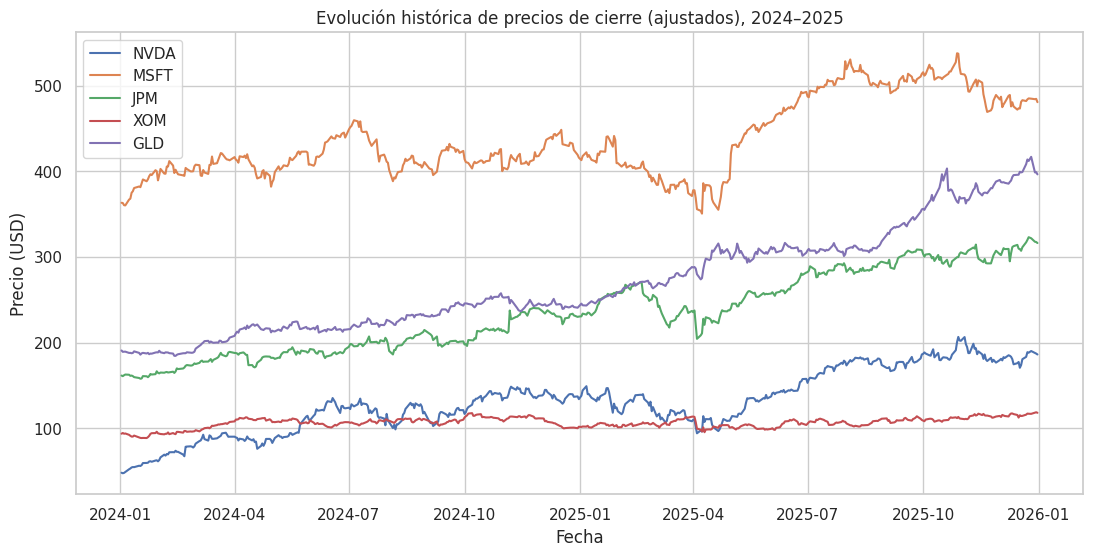

In [7]:
cierre = precios["Close"][activos].dropna()

fig, ax = plt.subplots(figsize=(13, 6))
for activo in activos:
    ax.plot(cierre.index, cierre[activo], label=activo)

ax.set_title("Evolución histórica de precios de cierre (ajustados), 2024–2025")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio (USD)")
ax.legend()
plt.show()

In [8]:
tabla_precios = pd.DataFrame({
    "Precio inicial": cierre.iloc[0],
    "Precio final": cierre.iloc[-1],
    "Mínimo": cierre.min(),
    "Máximo": cierre.max()
}).round(2)
tabla_precios

,Precio inicial,Precio final,Mínimo,Máximo
Ticker,,,,
NVDA,48.03,186.06,47.43,206.55
MSFT,363.12,480.57,350.45,537.65
JPM,161.47,316.13,157.76,322.95
XOM,93.60,117.97,88.52,118.61
GLD,190.72,396.31,184.42,416.74


In [9]:
mayor_nominal = cierre.iloc[-1].idxmax()
menor_nominal = cierre.iloc[-1].idxmin()
display(Markdown(f'''
**Interpretación:** el gráfico muestra **niveles de precio en dólares**, y los activos están en escalas muy distintas:
al final del período el precio más alto es el de **{mayor_nominal}** (USD {cierre.iloc[-1][mayor_nominal]:,.2f})
y el más bajo el de **{menor_nominal}** (USD {cierre.iloc[-1][menor_nominal]:,.2f}).
Por eso este gráfico **no sirve para comparar qué activo creció más**: una línea "más alta" solo indica un precio por acción mayor,
y un mismo cambio porcentual se ve mucho más grande en un activo caro que en uno barato. Para comparar crecimiento hay que normalizar (paso 4).
'''))


**Interpretación:** el gráfico muestra **niveles de precio en dólares**, y los activos están en escalas muy distintas:
al final del período el precio más alto es el de **MSFT** (USD 480.57)
y el más bajo el de **XOM** (USD 117.97).
Por eso este gráfico **no sirve para comparar qué activo creció más**: una línea "más alta" solo indica un precio por acción mayor,
y un mismo cambio porcentual se ve mucho más grande en un activo caro que en uno barato. Para comparar crecimiento hay que normalizar (paso 4).


# Paso 4 — Normalización (base 100)

$$\text{Índice}_t = \frac{P_t}{P_0}\times 100$$

**Pregunta:** ¿cómo cambió cada activo respecto a su propio punto inicial?

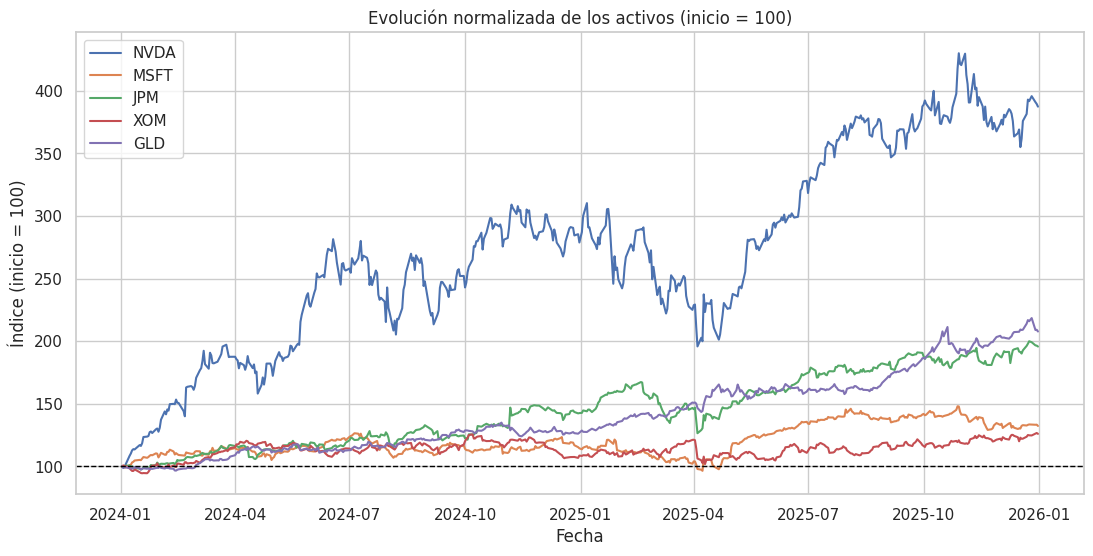

In [10]:
cierre_normalizado = cierre / cierre.iloc[0] * 100

fig, ax = plt.subplots(figsize=(13, 6))
for activo in activos:
    ax.plot(cierre_normalizado.index, cierre_normalizado[activo], label=activo)

ax.axhline(100, color="black", linewidth=1, linestyle="--")
ax.set_title("Evolución normalizada de los activos (inicio = 100)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Índice (inicio = 100)")
ax.legend()
plt.show()

In [11]:
rend_acumulado = (cierre.iloc[-1] / cierre.iloc[0] - 1).sort_values(ascending=False)
ranking = pd.DataFrame({
    "Índice final (base 100)": cierre_normalizado.iloc[-1][rend_acumulado.index].round(1),
    "Rendimiento acumulado": rend_acumulado.map(pct)
})
ranking

,Índice final (base 100),Rendimiento acumulado
Ticker,,
NVDA,387.4,287.40%
GLD,207.8,107.80%
JPM,195.8,95.78%
MSFT,132.3,32.35%
XOM,126.0,26.04%


In [12]:
mejor, peor = rend_acumulado.index[0], rend_acumulado.index[-1]
display(Markdown(f'''
**Interpretación:** al poner todos los activos en la misma base, la comparación cambia de pregunta: ya no es "¿cuál cuesta más?"
sino "¿cuánto creció cada uno desde su inicio?". En el período, **{mejor}** tuvo el mayor crecimiento acumulado
({pct(rend_acumulado[mejor], 1)}), mientras que **{peor}** tuvo el menor ({pct(rend_acumulado[peor], 1)}).
La línea punteada en 100 marca el punto de partida: lo que está por encima ganó valor y lo que está por debajo lo perdió.
Este gráfico describe el pasado; no implica que el activo con mejor desempeño vaya a mantenerlo.
'''))


**Interpretación:** al poner todos los activos en la misma base, la comparación cambia de pregunta: ya no es "¿cuál cuesta más?"
sino "¿cuánto creció cada uno desde su inicio?". En el período, **NVDA** tuvo el mayor crecimiento acumulado
(287.4%), mientras que **XOM** tuvo el menor (26.0%).
La línea punteada en 100 marca el punto de partida: lo que está por encima ganó valor y lo que está por debajo lo perdió.
Este gráfico describe el pasado; no implica que el activo con mejor desempeño vaya a mantenerlo.


# Paso 5 — Rendimientos diarios

$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$$

El primer día queda en `NaN` porque no tiene precio anterior; lo elimino.

In [13]:
rendimientos = cierre.pct_change().dropna()
rendimientos.head()

Ticker,NVDA,MSFT,JPM,XOM,GLD
Date,,,,,
2024-01-03,-0.012436,-0.000728,-0.004358,0.008402,-0.008337
2024-01-04,0.009018,-0.007177,0.006636,-0.008719,0.001005
2024-01-05,0.022897,-0.000516,0.005017,0.003030,0.000158
2024-01-08,0.064281,0.018871,-0.001451,-0.016662,-0.007816
2024-01-09,0.016975,0.002936,-0.007906,-0.012386,0.000319


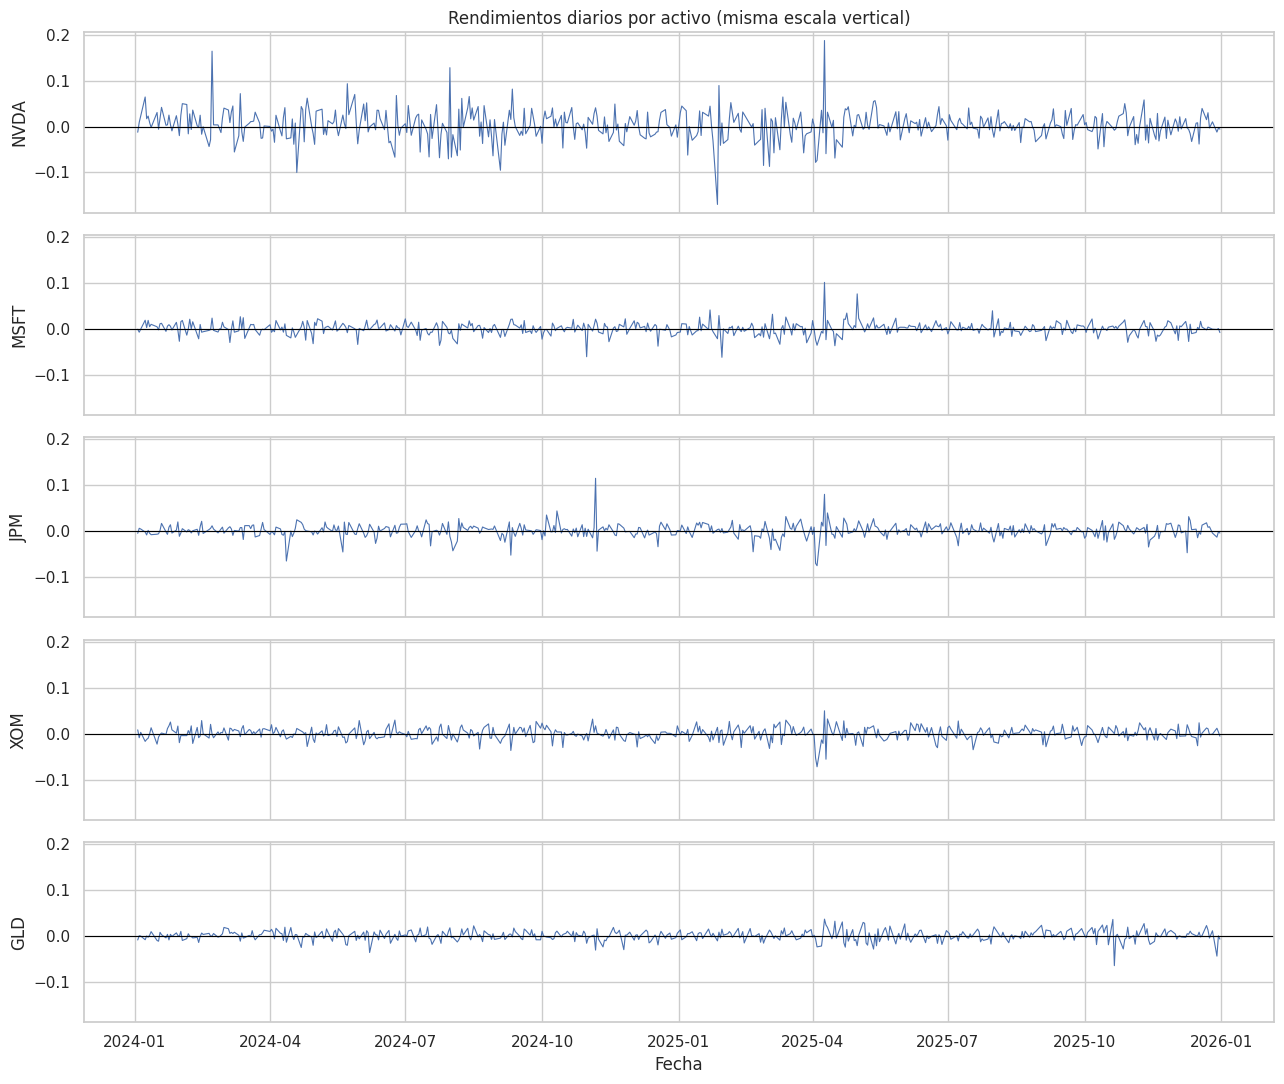

In [14]:
# Rendimientos a lo largo del tiempo: un panel por activo (misma escala en Y para poder comparar)
fig, axes = plt.subplots(len(activos), 1, figsize=(13, 11), sharex=True, sharey=True)

for ax, activo in zip(axes, activos):
    ax.plot(rendimientos.index, rendimientos[activo], linewidth=0.8)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel(activo)

axes[0].set_title("Rendimientos diarios por activo (misma escala vertical)")
axes[-1].set_xlabel("Fecha")
plt.tight_layout()
plt.show()

**Interpretación:** separé los activos en paneles con la **misma escala vertical**, porque al poner cinco series de rendimientos en un solo gráfico las líneas se tapan unas con otras. Así se ve directamente qué activo oscila más alrededor de cero. Los rendimientos se mueven alrededor de 0 sin tendencia clara: la tendencia que se veía en los precios no aparece aquí, porque cada valor es solo el cambio de *un* día. Lo que sí se ve son **períodos de mayor variabilidad** (*volatility clustering*): los días de movimientos grandes tienden a aparecer agrupados, y en algunas fechas varios activos tienen picos al mismo tiempo (lo analizo en el reto final, pregunta 4).

# Paso 6 — Distribución (histograma)

**Pregunta:** ¿cómo se distribuyen los rendimientos diarios de NVDA?

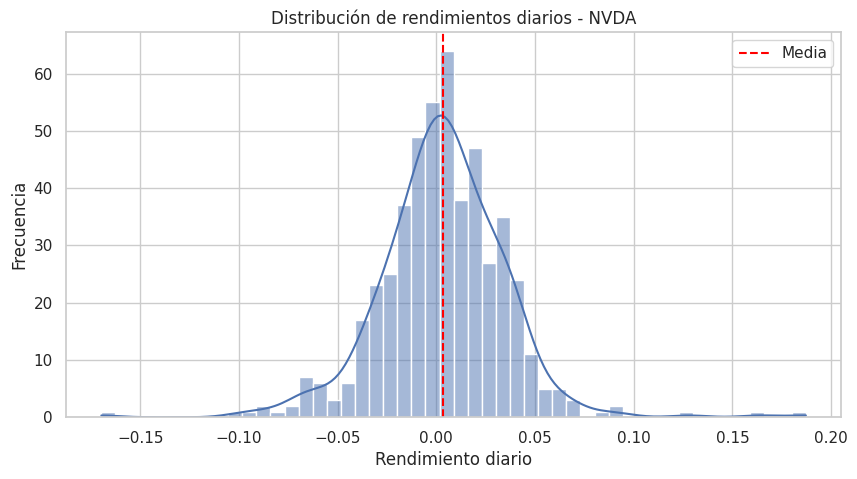

In [15]:
activo_hist = "NVDA"

plt.figure(figsize=(10, 5))
sns.histplot(data=rendimientos, x=activo_hist, bins=50, kde=True)
plt.axvline(rendimientos[activo_hist].mean(), color="red", linestyle="--", label="Media")
plt.title(f"Distribución de rendimientos diarios - {activo_hist}")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

In [16]:
r = rendimientos[activo_hist]
asim, curt = r.skew(), r.kurt()
display(Markdown(f'''
**Interpretación ({activo_hist}):**

- **Centro:** la media diaria es {pct(r.mean(), 3)} y la mediana {pct(r.median(), 3)}; ambas muy cerca de cero,
  lo normal en rendimientos diarios.
- **Dispersión:** la desviación estándar es {pct(r.std())} diario; la mayoría de los días el rendimiento está entre
  {pct(r.quantile(0.05))} y {pct(r.quantile(0.95))} (percentiles 5 y 95).
- **Colas / extremos:** el peor día fue {pct(r.min())} y el mejor {pct(r.max())}.
  La curtosis en exceso es {curt:.2f}; un valor mayor que 0 indica **colas más pesadas que una distribución normal**,
  es decir, días extremos más frecuentes de lo que predeciría una normal.
- **Forma:** la asimetría es {asim:.2f} ({"cola izquierda (caídas fuertes) algo más larga" if asim < -0.1 else "cola derecha (subidas fuertes) algo más larga" if asim > 0.1 else "aproximadamente simétrica"}).
'''))


**Interpretación (NVDA):**

- **Centro:** la media diaria es 0.322% y la mediana 0.350%; ambas muy cerca de cero,
  lo normal en rendimientos diarios.
- **Dispersión:** la desviación estándar es 3.22% diario; la mayoría de los días el rendimiento está entre
  -4.69% y 4.76% (percentiles 5 y 95).
- **Colas / extremos:** el peor día fue -16.97% y el mejor 18.72%.
  La curtosis en exceso es 5.00; un valor mayor que 0 indica **colas más pesadas que una distribución normal**,
  es decir, días extremos más frecuentes de lo que predeciría una normal.
- **Forma:** la asimetría es 0.18 (cola derecha (subidas fuertes) algo más larga).


## Profundización (guía S18, bloque 01): ¿el histograma depende de los *bins*?

Repito el mismo histograma con 10, 50 y 200 *bins*, y con `bins="auto"`. Además calculo cuántos *bins* recomiendan las reglas de **Sturges** ($k = 1 + \log_2 n$) y **Freedman–Diaconis** (ancho $= 2\cdot IQR/\sqrt[3]{n}$).

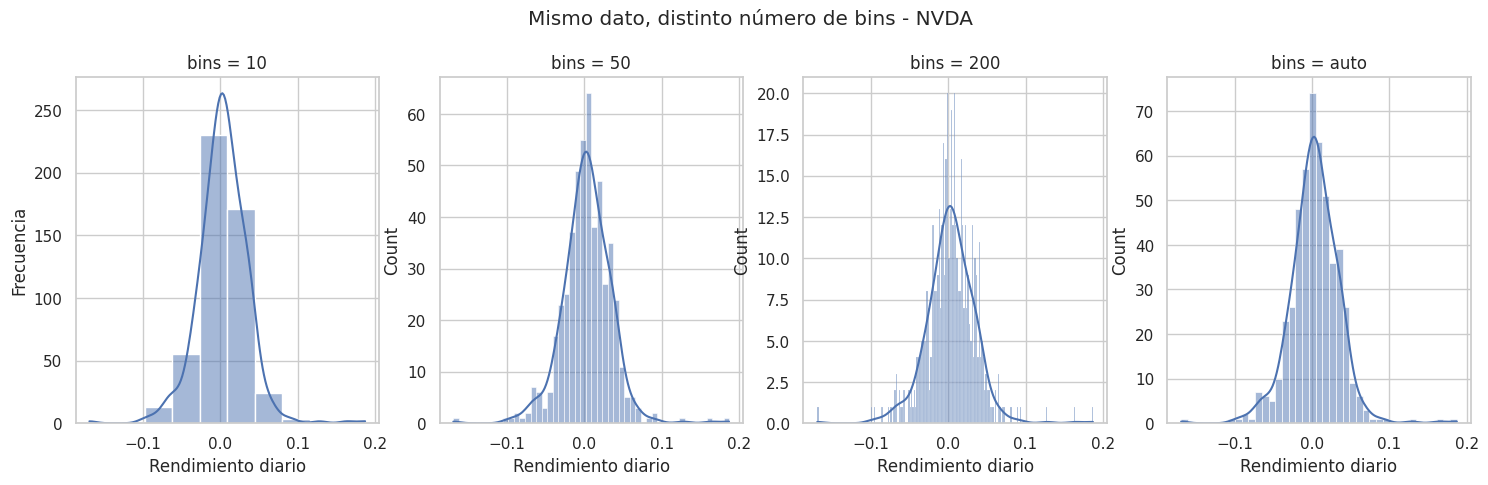

n = 501 observaciones
Sturges:          10 bins  (1 + log2(n) = 10.0)
Freedman-Diaconis: 41 bins
'auto' (NumPy):    41 bins


In [17]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharex=True)
for ax, b in zip(axes, [10, 50, 200, "auto"]):
    sns.histplot(r, bins=b, kde=True, ax=ax)
    ax.set_title(f"bins = {b}")
    ax.set_xlabel("Rendimiento diario")
axes[0].set_ylabel("Frecuencia")
fig.suptitle(f"Mismo dato, distinto número de bins - {activo_hist}", y=1.03)
plt.show()

n = len(r)
k_sturges = len(np.histogram_bin_edges(r, bins="sturges")) - 1
k_fd = len(np.histogram_bin_edges(r, bins="fd")) - 1
k_auto = len(np.histogram_bin_edges(r, bins="auto")) - 1
print(f"n = {n} observaciones")
print(f"Sturges:          {k_sturges} bins  (1 + log2(n) = {1 + np.log2(n):.1f})")
print(f"Freedman-Diaconis: {k_fd} bins")
print(f"'auto' (NumPy):    {k_auto} bins")

**Respuesta a la pregunta de análisis:** con **10 bins** la distribución se ve como una campana gruesa y los días extremos quedan escondidos dentro de las barras de los lados (sobre-suavizado). Con **200 bins** cada barra tiene muy pocas observaciones y aparecen "picos" y huecos que son ruido aleatorio, no una propiedad real de los datos. Con 50 bins o con `"auto"` se ve una forma intermedia.

Sin embargo, **la conclusión sobre el centro y la dispersión no cambia**: en los cuatro gráficos el centro está cerca de cero y el rango de los datos es el mismo, porque esas son propiedades de los datos (la media, la desviación estándar y los cuantiles no dependen de los *bins*). Lo que sí cambia es la impresión visual de la *forma* (qué tan "puntiaguda" parece o si parece tener varias modas). Por eso la conclusión original era sólida en lo que se apoyaba en estadísticas, y frágil en lo que se apoyaba solo en el dibujo. Para rendimientos financieros, que tienen colas pesadas, Freedman–Diaconis es más adecuada que Sturges porque usa el IQR y no se deja arrastrar por los valores extremos.

# Paso 7 — Comparación de la dispersión (boxplot)

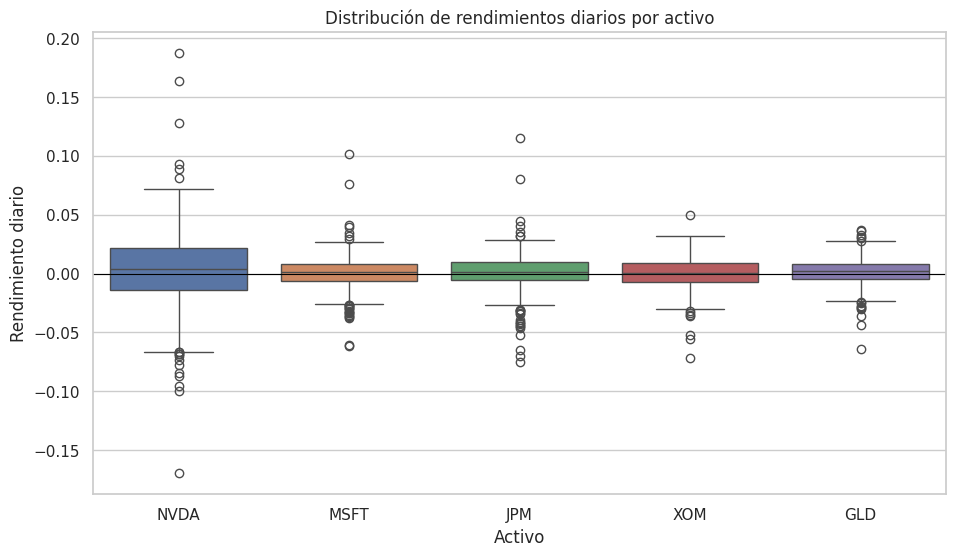

In [18]:
plt.figure(figsize=(11, 6))
sns.boxplot(data=rendimientos)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Distribución de rendimientos diarios por activo")
plt.xlabel("Activo")
plt.ylabel("Rendimiento diario")
plt.show()

In [19]:
# Regla de Tukey: cuántos días quedan fuera de los bigotes en cada activo
def limites_tukey(s, whis=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - whis * iqr, q3 + whis * iqr

filas = {}
for a in activos:
    s = rendimientos[a]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    li, ls = limites_tukey(s, 1.5)
    li3, ls3 = limites_tukey(s, 3.0)
    filas[a] = {
        "Q1": pct(q1), "Mediana": pct(s.median()), "Q3": pct(q3), "IQR": pct(q3 - q1),
        "Límite inf. (1.5)": pct(li), "Límite sup. (1.5)": pct(ls),
        "Atípicos whis=1.5": int(((s < li) | (s > ls)).sum()),
        "Atípicos whis=3.0": int(((s < li3) | (s > ls3)).sum()),
    }
tukey = pd.DataFrame(filas).T
tukey

,Q1,Mediana,Q3,IQR,Límite inf. (1.5),Límite sup. (1.5),Atípicos whis=1.5,Atípicos whis=3.0
NVDA,-1.36%,0.35%,2.17%,3.53%,-6.66%,7.46%,18,4
MSFT,-0.61%,0.11%,0.78%,1.39%,-2.69%,2.86%,24,4
JPM,-0.54%,0.17%,0.95%,1.48%,-2.76%,3.17%,24,6
XOM,-0.69%,0.06%,0.94%,1.63%,-3.13%,3.38%,8,1
GLD,-0.44%,0.18%,0.83%,1.27%,-2.35%,2.74%,15,2


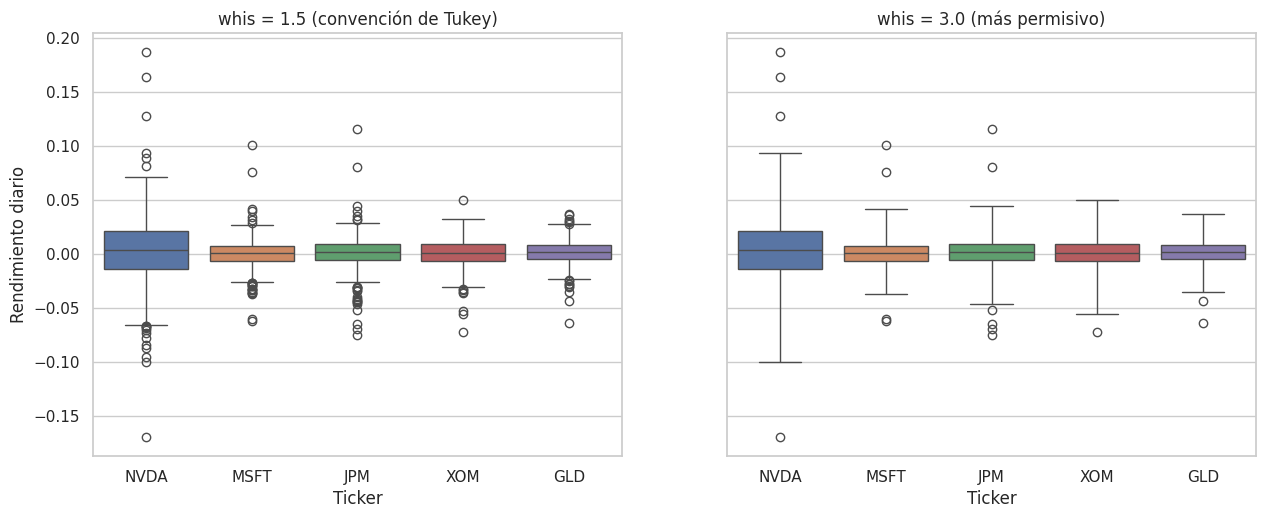

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
sns.boxplot(data=rendimientos, whis=1.5, ax=axes[0])
axes[0].set_title("whis = 1.5 (convención de Tukey)")
sns.boxplot(data=rendimientos, whis=3.0, ax=axes[1])
axes[1].set_title("whis = 3.0 (más permisivo)")
axes[0].set_ylabel("Rendimiento diario")
plt.show()

In [21]:
iqr_serie = rendimientos.quantile(0.75) - rendimientos.quantile(0.25)
mas_disp, menos_disp = iqr_serie.idxmax(), iqr_serie.idxmin()
atip = tukey["Atípicos whis=1.5"].astype(int)
display(Markdown(f'''
**Interpretación:**

1. **Mayor dispersión:** **{mas_disp}** tiene la caja más ancha (IQR = {pct(iqr_serie[mas_disp])}) y bigotes más largos;
   **{menos_disp}** es el más concentrado (IQR = {pct(iqr_serie[menos_disp])}).
2. **Observaciones alejadas:** el activo con más días fuera de los bigotes es **{atip.idxmax()}** ({atip.max()} días);
   el que menos tiene es **{atip.idxmin()}** ({atip.min()} días). Con `whis=3.0` el número de puntos marcados baja mucho,
   lo que muestra que "atípico" depende de una convención y no es algo que el programa descubre en los datos.
3. **Medianas:** todas están muy cerca de cero, como es típico en rendimientos diarios.
4. **Qué perderíamos mirando solo el precio:** el gráfico de precios muestra hacia dónde fue cada activo, pero no
   **qué tan accidentado fue el camino**. El boxplot muestra el riesgo día a día: dos activos pueden terminar con un crecimiento parecido
   y uno de ellos haber tenido oscilaciones diarias mucho mayores.
'''))


**Interpretación:**

1. **Mayor dispersión:** **NVDA** tiene la caja más ancha (IQR = 3.53%) y bigotes más largos;
   **GLD** es el más concentrado (IQR = 1.27%).
2. **Observaciones alejadas:** el activo con más días fuera de los bigotes es **MSFT** (24 días);
   el que menos tiene es **XOM** (8 días). Con `whis=3.0` el número de puntos marcados baja mucho,
   lo que muestra que "atípico" depende de una convención y no es algo que el programa descubre en los datos.
3. **Medianas:** todas están muy cerca de cero, como es típico en rendimientos diarios.
4. **Qué perderíamos mirando solo el precio:** el gráfico de precios muestra hacia dónde fue cada activo, pero no
   **qué tan accidentado fue el camino**. El boxplot muestra el riesgo día a día: dos activos pueden terminar con un crecimiento parecido
   y uno de ellos haber tenido oscilaciones diarias mucho mayores.


### Profundización (guía S18, bloque 02): ¿atípico = error?

Según la regla de Tukey, un día se dibuja fuera de los bigotes si su rendimiento está por debajo de $Q_1 - 1.5\cdot IQR$ o por encima de $Q_3 + 1.5\cdot IQR$. Si el **mismo día** aparece como atípico en varios activos a la vez, eso indica que fue un día muy distinto del comportamiento típico de todo el portafolio, probablemente por un **evento que afectó al mercado en general** (un anuncio de política económica, un dato macroeconómico, etc.) y no por algo propio de una empresa.

**"Atípico según el IQR" no es lo mismo que "error en los datos".** Un error sería un precio mal registrado; un atípico es un movimiento real pero poco frecuente. En finanzas esos días son justamente los más importantes para medir el riesgo, así que **no se deben eliminar** solo por estar fuera de los bigotes: primero hay que verificar si corresponden a un evento real (en la pregunta 4 del reto reviso las fechas concretas).

# Paso 8 — Matriz de correlación

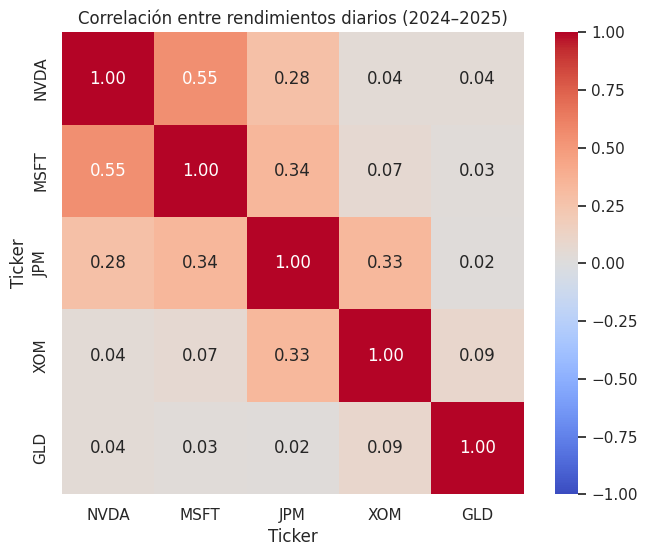

In [22]:
correlacion = rendimientos.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlación entre rendimientos diarios (2024–2025)")
plt.show()

In [23]:
# Pares ordenados de mayor a menor correlación (sin la diagonal ni duplicados)
mascara = np.triu(np.ones(correlacion.shape, dtype=bool), k=1)
pares = (correlacion.where(mascara).stack().dropna()
         .sort_values(ascending=False)
         .rename("Correlación"))
pares.index = [f"{a} – {b}" for a, b in pares.index]
corr_promedio = pares.mean()
corr_tech = correlacion.loc["NVDA", "MSFT"]
corr_otros = pares.drop("NVDA – MSFT", errors="ignore").drop("MSFT – NVDA", errors="ignore").mean()
print(f"Correlación NVDA–MSFT (mismo sector): {corr_tech:.2f}  |  promedio del resto de pares: {corr_otros:.2f}")
print(f"Correlación promedio entre pares: {corr_promedio:.2f}")
pares.round(2).to_frame()

Correlación NVDA–MSFT (mismo sector): 0.55  |  promedio del resto de pares: 0.14
Correlación promedio entre pares: 0.18


,Correlación
NVDA – MSFT,0.55
MSFT – JPM,0.34
JPM – XOM,0.33
NVDA – JPM,0.28
XOM – GLD,0.09
MSFT – XOM,0.07
NVDA – XOM,0.04
NVDA – GLD,0.04
MSFT – GLD,0.03
JPM – GLD,0.02


In [24]:
par_max, par_min = pares.index[0], pares.index[-1]
display(Markdown(f'''
**Interpretación:** el par con mayor correlación es **{par_max}** ({pares.iloc[0]:.2f}) y el de menor correlación es
**{par_min}** ({pares.iloc[-1]:.2f}). La correlación promedio entre todos los pares es **{corr_promedio:.2f}**,
{"por debajo" if corr_promedio < 0.5 else "por encima"} del umbral de referencia de 0.5 mencionado en la guía,
lo que {"sugiere un nivel de diversificación razonable" if corr_promedio < 0.5 else "sugiere que los activos tienden a moverse juntos"}.
{"La mezcla de sectores se refleja en la matriz: el par del mismo sector (NVDA – MSFT) tiene una correlación de " + f"{corr_tech:.2f}" + ", mayor que el promedio de los pares que mezclan sectores (" + f"{corr_otros:.2f}" + ")." if corr_tech > corr_otros else "Llama la atención que el par del mismo sector (NVDA – MSFT, " + f"{corr_tech:.2f}" + ") no está más correlacionado que el promedio del resto (" + f"{corr_otros:.2f}" + "), así que el sector por sí solo no explica la estructura de correlaciones."} Recordar que esta es una correlación **histórica** y **lineal** para 2024–2025: puede cambiar en otro período.
'''))


**Interpretación:** el par con mayor correlación es **NVDA – MSFT** (0.55) y el de menor correlación es
**JPM – GLD** (0.02). La correlación promedio entre todos los pares es **0.18**,
por debajo del umbral de referencia de 0.5 mencionado en la guía,
lo que sugiere un nivel de diversificación razonable.
La mezcla de sectores se refleja en la matriz: el par del mismo sector (NVDA – MSFT) tiene una correlación de 0.55, mayor que el promedio de los pares que mezclan sectores (0.14). Recordar que esta es una correlación **histórica** y **lineal** para 2024–2025: puede cambiar en otro período.


# Paso 9 — Relación entre dos activos (scatter plot)

Comparo el par **más** correlacionado con el par **menos** correlacionado, para ver cómo se ve esa diferencia en las observaciones individuales.

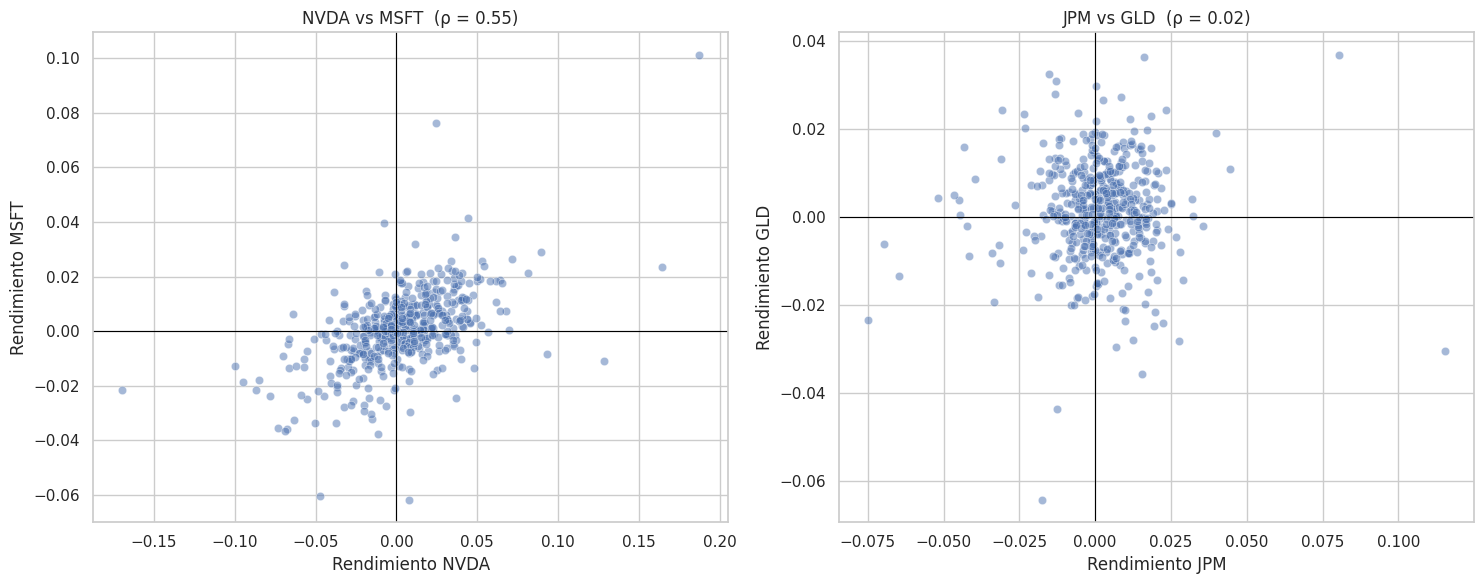

In [25]:
a1, b1 = par_max.split(" – ")
a2, b2 = par_min.split(" – ")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (x, y) in zip(axes, [(a1, b1), (a2, b2)]):
    sns.scatterplot(data=rendimientos, x=x, y=y, alpha=0.5, ax=ax)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{x} vs {y}  (ρ = {correlacion.loc[x, y]:.2f})")
    ax.set_xlabel(f"Rendimiento {x}")
    ax.set_ylabel(f"Rendimiento {y}")
plt.tight_layout()
plt.show()

In [26]:
mismo_signo_max = (np.sign(rendimientos[a1]) == np.sign(rendimientos[b1])).mean()
mismo_signo_min = (np.sign(rendimientos[a2]) == np.sign(rendimientos[b2])).mean()
dias_neg = rendimientos[a1] < 0
display(Markdown(f'''
**Interpretación:**

- **{a1} vs {b1}:** la nube tiene una orientación ascendente: la mayoría de puntos está en los cuadrantes I y III
  (ambos suben o ambos bajan). Los dos activos tuvieron el mismo signo el **{pct(mismo_signo_max, 1)}** de los días,
  y cuando {a1} cayó, {b1} también cayó el {pct((rendimientos.loc[dias_neg, b1] < 0).mean(), 1)} de esas veces.
  Aun así, la relación **no es perfectamente lineal**: hay bastante dispersión y algunos días extremos alejados de la nube.
- **{a2} vs {b2}:** la nube es mucho más redonda y sin una orientación clara; coincidieron en signo solo el
  **{pct(mismo_signo_min, 1)}** de los días, cerca de lo que se esperaría por azar (50%).
'''))


**Interpretación:**

- **NVDA vs MSFT:** la nube tiene una orientación ascendente: la mayoría de puntos está en los cuadrantes I y III
  (ambos suben o ambos bajan). Los dos activos tuvieron el mismo signo el **67.7%** de los días,
  y cuando NVDA cayó, MSFT también cayó el 65.2% de esas veces.
  Aun así, la relación **no es perfectamente lineal**: hay bastante dispersión y algunos días extremos alejados de la nube.
- **JPM vs GLD:** la nube es mucho más redonda y sin una orientación clara; coincidieron en signo solo el
  **53.9%** de los días, cerca de lo que se esperaría por azar (50%).


# Estadísticas descriptivas del portafolio

Complemento los gráficos con medidas numéricas. Agrego la **volatilidad anualizada** ($\sigma_{\text{diaria}}\cdot\sqrt{252}$), que es la forma usual de reportar la volatilidad.

In [27]:
resumen = pd.DataFrame({
    "Media diaria": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desv. estándar diaria": rendimientos.std(),
    "Volatilidad anualizada": rendimientos.std() * np.sqrt(252),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max(),
    "Rend. acumulado": cierre.iloc[-1] / cierre.iloc[0] - 1,
}).sort_values("Desv. estándar diaria", ascending=False)

resumen.style.format("{:.2%}")

,Media diaria,Mediana,Desv. estándar diaria,Volatilidad anualizada,Mínimo,Máximo,Rend. acumulado
Ticker,,,,,,,
NVDA,0.32%,0.35%,3.22%,51.09%,-16.97%,18.72%,287.40%
JPM,0.15%,0.17%,1.52%,24.17%,-7.48%,11.54%,95.78%
MSFT,0.07%,0.11%,1.40%,22.18%,-6.18%,10.13%,32.35%
XOM,0.06%,0.06%,1.35%,21.36%,-7.20%,4.99%,26.04%
GLD,0.15%,0.18%,1.11%,17.61%,-6.43%,3.70%,107.80%


# Paso 10 — Conclusiones: 3 hallazgos

In [28]:
vol = rendimientos.std()
v_max, v_min = vol.idxmax(), vol.idxmin()
ratio = vol[v_max] / vol[v_min]
mismo = (mejor == v_max)

display(Markdown(f'''
### Hallazgo 1 — Riesgo

> **Gráfico:** boxplot de rendimientos diarios (paso 7) y tabla de estadísticas.
> **Observación:** {v_max} tiene la mayor dispersión (desv. estándar diaria de {pct(vol[v_max])}, volatilidad anualizada de
> {pct(vol[v_max]*np.sqrt(252), 1)}), unas {ratio:.1f} veces la de {v_min}, que es el activo más estable ({pct(vol[v_min])} diario).
> **Interpretación:** {v_max} es el activo con mayor riesgo histórico del portafolio: sus días "normales" se mueven en un rango mucho más amplio,
> y por tanto también sus pérdidas posibles en un día cualquiera son mayores.

### Hallazgo 2 — Diversificación

> **Gráfico:** matriz de correlación (paso 8) y scatter plots (paso 9).
> **Observación:** la correlación más alta es {par_max} ({pares.iloc[0]:.2f}) y la más baja {par_min} ({pares.iloc[-1]:.2f});
> la correlación promedio es {corr_promedio:.2f}.
> **Interpretación:** {"combinar activos de sectores distintos sí reduce qué tan juntos se mueven" if corr_tech > corr_otros else "la diversificación depende de los pares concretos más que del sector"}: {par_min} aporta mucha más diversificación que
> {par_max}. Un portafolio formado solo por activos como {a1} y {b1} estaría más expuesto a que todo caiga al mismo tiempo.

### Hallazgo 3 — Rendimiento vs. riesgo

> **Gráfico:** evolución normalizada (paso 4) comparada con el boxplot (paso 7).
> **Observación:** {mejor} tuvo el mayor crecimiento acumulado ({pct(rend_acumulado[mejor], 1)}) y {peor} el menor
> ({pct(rend_acumulado[peor], 1)}). {"El activo que más creció es también el más volátil." if mismo else f"El activo que más creció ({mejor}) no es el más volátil ({v_max})."}
> **Interpretación:** {"en este período un mayor rendimiento vino acompañado de mayor riesgo, lo que es coherente con la idea de que el rendimiento extra se paga con mayor volatilidad." if mismo else "en este período el mayor rendimiento no fue simplemente una compensación por mayor volatilidad, lo que muestra que mirar solo una de las dos dimensiones es incompleto."}
> Este resultado describe 2024–2025 y no es una recomendación de inversión.
'''))


### Hallazgo 1 — Riesgo

> **Gráfico:** boxplot de rendimientos diarios (paso 7) y tabla de estadísticas.
> **Observación:** NVDA tiene la mayor dispersión (desv. estándar diaria de 3.22%, volatilidad anualizada de
> 51.1%), unas 2.9 veces la de GLD, que es el activo más estable (1.11% diario).
> **Interpretación:** NVDA es el activo con mayor riesgo histórico del portafolio: sus días "normales" se mueven en un rango mucho más amplio,
> y por tanto también sus pérdidas posibles en un día cualquiera son mayores.

### Hallazgo 2 — Diversificación

> **Gráfico:** matriz de correlación (paso 8) y scatter plots (paso 9).
> **Observación:** la correlación más alta es NVDA – MSFT (0.55) y la más baja JPM – GLD (0.02);
> la correlación promedio es 0.18.
> **Interpretación:** combinar activos de sectores distintos sí reduce qué tan juntos se mueven: JPM – GLD aporta mucha más diversificación que
> NVDA – MSFT. Un portafolio formado solo por activos como NVDA y MSFT estaría más expuesto a que todo caiga al mismo tiempo.

### Hallazgo 3 — Rendimiento vs. riesgo

> **Gráfico:** evolución normalizada (paso 4) comparada con el boxplot (paso 7).
> **Observación:** NVDA tuvo el mayor crecimiento acumulado (287.4%) y XOM el menor
> (26.0%). El activo que más creció es también el más volátil.
> **Interpretación:** en este período un mayor rendimiento vino acompañado de mayor riesgo, lo que es coherente con la idea de que el rendimiento extra se paga con mayor volatilidad.
> Este resultado describe 2024–2025 y no es una recomendación de inversión.


# Reto final 🎯

In [29]:
# Pregunta 4: días con movimientos extremos simultáneos (fuera de los bigotes de Tukey en 3 o más activos)
extremos = pd.DataFrame(index=rendimientos.index)
for a in activos:
    li, ls = limites_tukey(rendimientos[a], 1.5)
    extremos[a] = (rendimientos[a] < li) | (rendimientos[a] > ls)

n_extremos = extremos.sum(axis=1)
dias_simultaneos = rendimientos[n_extremos >= 3].copy()
dias_simultaneos["Activos extremos"] = n_extremos[n_extremos >= 3]
dias_simultaneos.style.format({a: "{:.2%}" for a in activos})

Ticker,NVDA,MSFT,JPM,XOM,GLD,Activos extremos
Date,,,,,,
2025-04-03 00:00:00,-7.81%,-2.36%,-6.97%,-5.26%,-0.60%,3
2025-04-04 00:00:00,-7.36%,-3.56%,-7.48%,-7.20%,-2.34%,4
2025-04-09 00:00:00,18.72%,10.13%,8.06%,4.99%,3.70%,5
2025-04-16 00:00:00,-6.87%,-3.66%,-1.51%,1.06%,3.25%,3


In [30]:
if len(dias_simultaneos) > 0:
    peor_dia = rendimientos.mean(axis=1).idxmin()
    fechas = ", ".join(d.strftime("%Y-%m-%d") for d in dias_simultaneos.index)
    abril25 = any((d.year == 2025 and d.month == 4) for d in dias_simultaneos.index)
    texto_p4 = (f"**Sí.** Hubo {len(dias_simultaneos)} día(s) en que 3 o más activos tuvieron un movimiento atípico al mismo tiempo: {fechas}. "
                f"El día con el peor rendimiento promedio del portafolio fue el {peor_dia.strftime("%Y-%m-%d")}. ")
    if abril25:
        texto_p4 += ("Varios de estos días caen en **abril de 2025**, cuando EE. UU. anunció aranceles generalizados y luego una pausa parcial: "
                     "primero hubo caídas fuertes y, días después, un rebote igual de brusco. Es un ejemplo claro de un evento de mercado "
                     "que afecta a todos los sectores al tiempo, y justamente en esos días la diversificación protege menos. ")
    texto_p4 += "Estos puntos son movimientos reales del mercado, no errores de datos."
else:
    texto_p4 = "Con la regla de Tukey no aparece ningún día en que 3 o más activos sean atípicos simultáneamente."

cap = cierre.iloc[-1].idxmax()
display(Markdown(f'''
### Pregunta 1 — ¿Cuál activo presenta mayor dispersión de rendimientos?
**{v_max}**, con una desviación estándar diaria de {pct(vol[v_max])} y el IQR {"más amplio" if iqr_serie.idxmax() == v_max else f"(aunque por IQR el más amplio es {iqr_serie.idxmax()})"}.
En el boxplot es el que tiene la caja y los bigotes más largos.

### Pregunta 2 — ¿Cuáles dos activos presentan mayor correlación?
**{par_max}**, con ρ = {pares.iloc[0]:.2f}.

### Pregunta 3 — ¿Cuáles presentan menor correlación?
**{par_min}**, con ρ = {pares.iloc[-1]:.2f}.

### Pregunta 4 — ¿Existe algún día con movimientos extremos simultáneos?
{texto_p4}
'''))


### Pregunta 1 — ¿Cuál activo presenta mayor dispersión de rendimientos?
**NVDA**, con una desviación estándar diaria de 3.22% y el IQR más amplio.
En el boxplot es el que tiene la caja y los bigotes más largos.

### Pregunta 2 — ¿Cuáles dos activos presentan mayor correlación?
**NVDA – MSFT**, con ρ = 0.55.

### Pregunta 3 — ¿Cuáles presentan menor correlación?
**JPM – GLD**, con ρ = 0.02.

### Pregunta 4 — ¿Existe algún día con movimientos extremos simultáneos?
**Sí.** Hubo 4 día(s) en que 3 o más activos tuvieron un movimiento atípico al mismo tiempo: 2025-04-03, 2025-04-04, 2025-04-09, 2025-04-16. El día con el peor rendimiento promedio del portafolio fue el 2025-04-04. Varios de estos días caen en **abril de 2025**, cuando EE. UU. anunció aranceles generalizados y luego una pausa parcial: primero hubo caídas fuertes y, días después, un rebote igual de brusco. Es un ejemplo claro de un evento de mercado que afecta a todos los sectores al tiempo, y justamente en esos días la diversificación protege menos. Estos puntos son movimientos reales del mercado, no errores de datos.


### Pregunta 5 — ¿La evolución normalizada cuenta la misma historia que los precios originales?

**No.** El gráfico de precios originales responde "¿cuánto cuesta cada activo?", y está dominado por los activos de precio nominal más alto: sus movimientos se ven grandes y los de los activos baratos se ven planos aunque en porcentaje sean iguales o mayores. El gráfico normalizado responde "¿cuánto creció cada activo desde su punto de partida?", y es el que permite comparar desempeño. Con los precios originales se podría concluir erradamente que el activo con la línea más alta "le fue mejor", cuando solo es el más caro (comparar el paso 3 con el ranking del paso 4).

### Pregunta 6 — ¿Qué aporta el histograma que no aporta el gráfico temporal?

El gráfico temporal muestra **cuándo** ocurrió cada rendimiento y si hay períodos de mayor volatilidad. El histograma deja de lado el orden en el tiempo y muestra **con qué frecuencia** ocurre cada tamaño de rendimiento: dónde se concentran los días, qué tan dispersos están, si la distribución es simétrica y qué tan pesadas son las colas (cuántos días extremos hay comparado con una distribución normal). Eso no se puede leer en el gráfico temporal porque ahí los 500 puntos se ven como una línea que oscila.

### Pregunta 7 — ¿Qué aporta el scatter plot que no aporta el heatmap?

El heatmap resume toda la relación entre dos activos en **un solo número** (la correlación lineal). El scatter plot muestra **cada día por separado**, lo que permite ver si la relación realmente es lineal, si hay días extremos que están "inflando" o "bajando" la correlación, si la relación es más fuerte en las caídas que en las subidas, y cuántos días los activos se movieron en direcciones opuestas. Dos pares con la misma correlación pueden tener nubes de puntos muy distintas.

# Preguntas de profundización (guía S18)

### Bloque 03 — Correlación no es causalidad

La correlación entre dos activos de esta matriz no demuestra que uno cause los movimientos del otro. Aplicado a mi portafolio:

- **Causalidad directa:** es poco probable entre estos activos (que JPM suba no "provoca" que suba MSFT).
- **Variable de confusión:** es la explicación más probable de la correlación entre NVDA y MSFT: ambas dependen de los mismos factores (el auge de la inteligencia artificial, las expectativas sobre tasas de interés y el sentimiento general hacia el sector tecnológico). Lo mismo pasa con días de choques macro como los anuncios de aranceles, que mueven a todo el mercado a la vez.
- **Coincidencia:** con solo dos años de datos, una correlación moderada o baja (por ejemplo con GLD o XOM) podría cambiar bastante en otro período. Por eso no debería tomarse como una propiedad fija de los activos.

Ejemplos clásicos de correlaciones sin causalidad: el consumo de **margarina** y los **divorcios** en Maine (coincidencia), y las ventas de **helado** y los **ahogamientos** (variable de confusión: el calor del verano).

### Bloque 04 — De la matriz de correlación a la diversificación

Siguiendo a Markowitz (1952), lo que reduce el riesgo conjunto no es solo **cuántos** activos hay en el portafolio, sino **qué tan correlacionados** están. El par más correlacionado de mi análisis (ver paso 8) se comporta en buena medida como si fuera "medio activo duplicado": cuando uno cae, el otro tiende a caer también, así que tenerlos juntos aporta menos protección de la que parece. En cambio, los pares de correlación más baja de la matriz (ver tabla de pares del paso 8) sí amortiguan el riesgo, porque sus caídas no suelen coincidir.

Por eso un portafolio de cinco tecnológicas, como el del ejemplo de clase, puede tener menos diversificación real que un portafolio de cinco activos de sectores distintos, aunque el número de activos sea el mismo. Evans y Archer (1968) muestran además que agregar activos deja de reducir mucho el riesgo después de unos 10, **si** la composición del grupo no cambia.

---

## Regla de oro aplicada

- **¿Qué quería saber?** Cómo se comportaron, por separado y en conjunto, cinco activos de sectores distintos en 2024–2025.
- **¿Qué observé?** Diferencias grandes de crecimiento y de volatilidad entre activos, correlaciones más altas dentro del mismo sector, y algunos días en que todo el portafolio se movió a la vez.
- **¿Qué puedo concluir razonablemente?** Que la mezcla de sectores mejora la diversificación respecto a un portafolio solo tecnológico, pero que en los choques fuertes de mercado esa protección disminuye. Todo esto es descriptivo de un período pasado y **no constituye asesoría financiera**.

### Referencias

- Markowitz, H. (1952). Portfolio Selection. *The Journal of Finance*, 7(1), 77–91.
- Evans, J. L. & Archer, S. H. (1968). Diversification and the Reduction of Dispersion: An Empirical Analysis. *The Journal of Finance*, 23(5), 761–767.
- Documentación oficial de Matplotlib, Seaborn, pandas, NumPy (`histogram_bin_edges`) y yfinance.
- Irizarry, R. A. *Introducción a la Ciencia de Datos*. Harvard.